# Interactive attention analysis

Drills into a *single* instance at a time, rather than the aggregate
statistics in [`llava_error_attribution.ipynb`](../../notebooks/llava_error_attribution.ipynb) /
[`qwen_error_attribution.ipynb`](../../notebooks/qwen_error_attribution.ipynb): pick a
model, look at the failure patterns the field experiment produces, sample or choose
one concrete instance from a pattern of interest, then walk through what the model
actually saw and attended to - on the original image and on the white-bordered
"field" variant - side by side.

The actual model inference (answer + attention map, for both the original and
field-augmented image) runs in [`compute_attention.py`](compute_attention.py) as a
**separate one-shot process**, not inside this notebook's kernel. `attn_implementation
="eager"` on a 7B model, at large field values pushing toward Qwen's 16,384-vision-token
cap, can peak close to a GPU's full 80GB - re-loading/rerunning that inside a long-lived
kernel risks leaking memory across cell reruns, whereas a one-shot process always fully
releases its GPU memory on exit. This notebook only triggers that script and then loads
and analyzes/plots the `.npz` artifact it saves - it never itself holds a model or a GPU
allocation.

Flow:

1. select a model and categorize every field-experiment instance into one of
   four outcome patterns (reusing the scoring already produced by
   `src/parse_field_results.py`),
2. choose or randomly sample one instance from a chosen pattern,
3. show the original image, question, ground truth, and the model's answer
   on the original image (correct or not),
4. show where the model actually attended on the original image,
5. show the field-augmented image (added white border) at a chosen field
   size, and the model's answer on it (correct or not),
6. show where the model attended on that augmented image,
7. quantify how much of that attention mass fell on the real content versus
   the added white border.


## Setup


In [ ]:
import sys
from pathlib import Path

project_root = next(p for p in (Path().resolve(), *Path().resolve().parents)
                    if (p / "src" / "benchmarks.py").is_file() and (p / "scripts").is_dir())
notebook_dir = project_root / "scripts" / "attention_analysis"
for p in (notebook_dir, project_root):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

In [2]:
import json
import re
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from common import (
    MODEL_CONFIGS, content_box_in_field_img, content_area_fraction_grid,
    content_box_in_grid_cells, resample_grid,
)
from src.attention_viz import plot_attention_grid, desink_attention_grid
from src.parse_field_results import score_field_results, FIELD_VALUES, VARIANTS

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)


/home/colligo/Waldo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Select a model and categorize its field-experiment instances


In [3]:
MODEL_KEY = "qwen"  # one of "llava", "qwen", "pixtral", "llama"
CFG = MODEL_CONFIGS[MODEL_KEY]
print(f"Analyzing {CFG['model_hf_name']}")


Analyzing Qwen/Qwen2-VL-7B-Instruct


Each field-experiment instance is categorized by comparing the **field**
(bordered) score against the **resized** (borderless, same-content-resolution
control) score, restricted to instances the model got right at baseline
(field=0) - same scheme as the error-attribution notebooks:

| field | resized | category | meaning |
|---|---|---|---|
| correct | correct | `robust` | transformation didn't break it |
| correct | wrong | `control_only_failure` | the no-border downscale control broke, the bordered one didn't |
| wrong | correct | `field_only_failure` | the border broke it while the same-resolution, no-border control still worked |
| wrong | wrong | `shared_failure` | breaks either way - resolution loss, not the border, is the likely driver |


In [4]:
RESULTS_DIR = project_root / "results"
RESULTS_OLD_DIR = project_root / "results_old"
SCORED_DIR = project_root / "results_scored_field"
NEW_FIELD_VALUES = [float(v) for v in FIELD_VALUES if v != "0"]

model_results_dir = RESULTS_DIR / CFG["model_dir"]
try:
    if not model_results_dir.exists():
        raise FileNotFoundError(model_results_dir)
    field_df = score_field_results(RESULTS_DIR, RESULTS_OLD_DIR, SCORED_DIR, model=CFG["model_dir"], model_short=CFG["model_short"])
    BENCHMARKS = sorted(p.name for p in model_results_dir.iterdir() if p.is_dir())
    print(f"{len(BENCHMARKS)} benchmarks, field values {NEW_FIELD_VALUES} (+ shared baseline 0)")
except FileNotFoundError:
    field_df = None
    BENCHMARKS = []
    print(f"No field-experiment results found for {CFG['model_hf_name']!r} at {model_results_dir} - "
          f"the sweep for this model hasn't been run yet. Sections 1-2 (pattern analysis/sampling) "
          f"won't have data, but a hardcoded (benchmark, id, field) example still works directly "
          f"via compute_attention.py.")


15 benchmarks, field values [0.5, 1.0, 2.0, 3.0, 4.0, 5.0] (+ shared baseline 0)


In [5]:
def scored_path(variant, benchmark, value):
    return SCORED_DIR / CFG["model_dir"] / variant / benchmark / f"{benchmark}_{CFG['model_short']}_{variant}{value}.json"


def load_examples(path):
    with open(path) as f:
        return json.load(f)


def make_keys(examples):
    # (id, question, nth-occurrence) - stable join key across files whose row order differs.
    seen = {}
    keys = []
    for ex in examples:
        base = (ex.get("id"), ex.get("question"))
        n = seen.get(base, 0)
        seen[base] = n + 1
        keys.append(base + (n,))
    return keys


records = []
for benchmark in BENCHMARKS:
    baseline_path = scored_path("field", benchmark, "0")
    if not baseline_path.exists():
        continue
    baseline_examples = load_examples(baseline_path)
    baseline = dict(zip(make_keys(baseline_examples), baseline_examples))

    for variant in VARIANTS:
        for value in NEW_FIELD_VALUES:
            path = scored_path(variant, benchmark, f"{value:g}")
            if not path.exists():
                continue
            examples = load_examples(path)
            for key, ex in zip(make_keys(examples), examples):
                base_ex = baseline.get(key)
                if base_ex is None:
                    continue
                records.append({
                    "benchmark": benchmark,
                    "variant": variant,
                    "field_value": value,
                    "id": key[0],
                    "key": key,
                    "question": ex.get("question"),
                    "ground_truth": ex.get("ground_truth"),
                    "generated_answer": ex.get("generated_answer"),
                    "score": ex.get("score"),
                    "baseline_score": base_ex.get("score"),
                    "baseline_generated": base_ex.get("generated_answer"),
                })

RECORD_COLUMNS = [
    "benchmark", "variant", "field_value", "id", "key", "question", "ground_truth",
    "generated_answer", "score", "baseline_score", "baseline_generated",
]
df = pd.DataFrame(records, columns=RECORD_COLUMNS)
print(f"{len(df)} rows across {df['benchmark'].nunique()} benchmarks")


43038 rows across 12 benchmarks


In [6]:
wide = df.pivot_table(
    index=["benchmark", "key", "field_value"], columns="variant", values="score", aggfunc="first",
).reset_index()
wide.columns.name = None

meta_cols = df.drop_duplicates(["benchmark", "key"])[["benchmark", "key", "id", "question", "ground_truth", "baseline_score", "baseline_generated"]]
wide = wide.merge(meta_cols, on=["benchmark", "key"], how="left")


def categorize(row):
    if row["baseline_score"] != 1.0:
        return "baseline_wrong"
    if pd.isna(row["field"]) or pd.isna(row["resized"]):
        return "unscorable"
    if row["field"] == 1.0 and row["resized"] == 1.0:
        return "robust"
    if row["field"] == 0.0 and row["resized"] == 1.0:
        return "field_only_failure"
    if row["field"] == 1.0 and row["resized"] == 0.0:
        return "control_only_failure"
    return "shared_failure"


wide["category"] = wide.apply(categorize, axis=1)
wide["category"].value_counts()


category
robust                  7866
baseline_wrong          5046
field_only_failure       669
shared_failure           469
control_only_failure     296
Name: count, dtype: int64

### Pattern composition across the field-value sweep


In [7]:
CATEGORY_ORDER = ["robust", "control_only_failure", "shared_failure", "field_only_failure"]
CATEGORY_COLORS = {
    "robust": "#0072B2",
    "control_only_failure": "#009E73",
    "shared_failure": "#E69F00",
    "field_only_failure": "#D55E00",
}
CATEGORY_LABELS = {
    "robust": "Robust (all correct)",
    "control_only_failure": "Control-only failure (resized broke, field didn't)",
    "shared_failure": "Shared failure (field AND resized broke)",
    "field_only_failure": "Field-only failure (border broke it, resized control didn't)",
}

at_risk = wide[wide["category"] != "baseline_wrong"].copy()
comp = (
    at_risk.groupby(["field_value", "category"]).size()
    .unstack(fill_value=0)
    .reindex(columns=CATEGORY_ORDER, fill_value=0)
)
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100
comp_pct.round(1)


category,robust,control_only_failure,shared_failure,field_only_failure
field_value,,,,
0.5,91.9,1.7,2.0,4.5
1.0,90.4,2.1,3.0,4.5
2.0,86.2,2.5,4.1,7.2
3.0,82.5,4.2,5.5,7.9
4.0,80.5,3.7,6.6,9.2
5.0,76.1,4.9,9.2,9.9


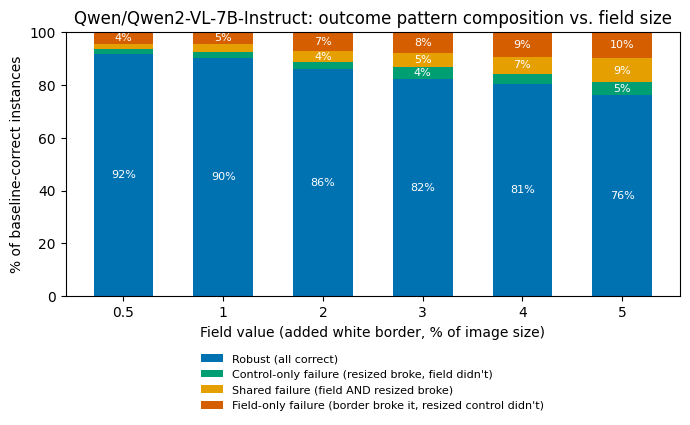

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(comp_pct.index))
bottom = np.zeros(len(comp_pct))
for cat in CATEGORY_ORDER:
    vals = comp_pct[cat].values
    ax.bar(x, vals, bottom=bottom, width=0.6, color=CATEGORY_COLORS[cat], label=CATEGORY_LABELS[cat])
    for xi, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 4:
            ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([f"{v:g}" for v in comp_pct.index])
ax.set_xlabel("Field value (added white border, % of image size)")
ax.set_ylabel("% of baseline-correct instances")
ax.set_title(f"{CFG['model_hf_name']}: outcome pattern composition vs. field size")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


## 2. Choose or sample an instance from a chosen pattern


In [9]:
FIELD_VALUE = 3.0                         # which field-experiment size to inspect (one of NEW_FIELD_VALUES)
SELECTED_CATEGORY = "field_only_failure"  # one of CATEGORY_ORDER
SELECTED_BENCHMARK = "MMVet"              # a specific benchmark name, or "ANY" to pool across all of them
SAMPLE_SEED = 0                           # change this to sample a different instance
INSTANCE_INDEX = None                     # set an integer instead of sampling, to browse candidates deterministically

candidates = wide[(wide["field_value"] == FIELD_VALUE) & (wide["category"] == SELECTED_CATEGORY)]
if SELECTED_BENCHMARK != "ANY":
    candidates = candidates[candidates["benchmark"] == SELECTED_BENCHMARK]
if candidates.empty:
    raise ValueError(f"No {SELECTED_CATEGORY!r} instances at field={FIELD_VALUE:g} "
                      f"(benchmark={SELECTED_BENCHMARK!r}) - try a different combination.")

row = candidates.iloc[INSTANCE_INDEX] if INSTANCE_INDEX is not None else candidates.sample(1, random_state=SAMPLE_SEED).iloc[0]

BENCHMARK = row["benchmark"]
TARGET_ID = row["id"]
print(f"{len(candidates)} candidates for category={SELECTED_CATEGORY!r} at field={FIELD_VALUE:g}"
      + ("" if SELECTED_BENCHMARK == "ANY" else f" in {SELECTED_BENCHMARK}"))
print(f"Selected: benchmark={BENCHMARK!r} id={TARGET_ID!r} "
      f"(field/resized/bicubic scores = {row['field']}/{row['resized']}/{row['bicubic']})")


5 candidates for category='field_only_failure' at field=3 in MMVet
Selected: benchmark='MMVet' id='v1_25' (field/resized/bicubic scores = 0.0/1.0/1.0)


In [10]:
#FIELD_VALUE = 5.0
#BENCHMARK = "MMVet"
#TARGET_ID = "v1_98"

#matched = wide[(wide["benchmark"] == BENCHMARK) & (wide["id"] == TARGET_ID) & (wide["field_value"] == FIELD_VALUE)]
#row = matched.iloc[0] if len(matched) else None
#print(f"Hardcoded: benchmark={BENCHMARK!r} id={TARGET_ID!r} field={FIELD_VALUE:g}"
#      + (f" (field/resized/bicubic scores = {row['field']}/{row['resized']}/{row['bicubic']})"
#         if row is not None else " (not found in `wide` for this model - stored category/scores unavailable)"))


## 3. Per-model visualizations

For every model, delegates to [`compute_attention.py`](compute_attention.py) (reusing a
cached `.npz` if one already exists) for the same `(BENCHMARK, TARGET_ID, FIELD_VALUE)`
instance from section 2, then prints all of that model's numbers under its own heading
and displays every visualization for it as its own separate, unannotated figure - both
model-input resizes, both attention maps, the content/border split, both top-k masks, and
the attention-sink before/after correction.

Also includes a blank-canvas control: the exact same question, asked against a plain
white image at the original size and again at the field size, with zero actual visual
content. A model landing on a plausible-looking answer anyway (rather than something
that reads as "I can't see anything") is a language-prior/hallucination tell, not
genuine visual grounding - e.g. LLaVA answered this notebook's own hardcoded example
with "Antarctica" (wrong, but a real continent) given nothing but a white square.


In [11]:
def show(image, cmap=None, vmax=None):
    """Display a single image/grid as its own standalone figure - no title, no axes."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image, cmap=cmap, vmax=vmax)
    ax.axis("off")
    plt.show()
    plt.close(fig)


def show_attention_overlay(model_view, attn_grid):
    """Attention heatmap overlaid on model_view, as its own standalone figure - no title."""
    from src.attention_viz import upsample_grid, ATTENTION_CMAP

    overlay = upsample_grid(attn_grid, model_view.size)
    vmax = float(np.percentile(attn_grid, 99))
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(model_view)
    ax.imshow(overlay, cmap=ATTENTION_CMAP, alpha=0.55, vmin=0, vmax=vmax)
    ax.axis("off")
    plt.show()
    plt.close(fig)


def show_mask(grid, mask, vmax=None):
    """Grid heatmap with a mask's boundary outlined in red, as its own standalone figure."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(grid, cmap="viridis", vmax=vmax if vmax is not None else grid.max())
    if mask.any():
        ax.contour(mask.astype(float), levels=[0.5], colors="red", linewidths=1.5)
    ax.axis("off")
    plt.show()
    plt.close(fig)


def show_content_border_bar(content_mass_frac, border_mass_frac):
    """Bare content-vs-border bar comparison, as its own standalone figure - no labels."""
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.bar([0, 1], [content_mass_frac * 100, border_mass_frac * 100], color=["#0072B2", "#D55E00"], width=0.6)
    ax.set_ylim(0, 100)
    ax.axis("off")
    plt.show()
    plt.close(fig)


def top_k_mask(grid, fraction):
    k = max(1, int(round(grid.size * fraction)))
    threshold = np.partition(grid.ravel(), -k)[-k]
    return grid >= threshold


def visualize_instance(model_key, benchmark, target_id, field_value,
                        top_k_fraction=0.10, sink_mass_threshold=0.15, force_recompute=False):
    """Run/load compute_attention.py's result for one model on one instance, print every
    number under a model-name header, then display every visualization for it as a
    separate, unannotated figure."""
    cfg = MODEL_CONFIGS[model_key]
    print(f"\n{'=' * 88}\n{cfg['model_hf_name']}\n{'=' * 88}")

    output_dir = notebook_dir / "results"
    output_dir.mkdir(exist_ok=True)
    safe_id = re.sub(r"[^A-Za-z0-9]+", "_", str(target_id)).strip("_")
    artifact_path = output_dir / f"{model_key}_{benchmark}_{safe_id}_field{field_value:g}.npz"

    if artifact_path.exists() and not force_recompute:
        print(f"Reusing cached result at {artifact_path}")
    else:
        cmd = [
            sys.executable, str(notebook_dir / "compute_attention.py"),
            "--model", model_key, "--benchmark", benchmark, "--id", str(target_id),
            "--field", str(field_value), "--output-dir", str(output_dir),
        ]
        print("Running:", " ".join(cmd))
        # A CUDA error mid-run (e.g. an "unspecified launch failure" - observed in practice
        # when a model gets moved across GPUs mid-session on this shared cluster) typically
        # leaves the process's CUDA context unusable for the rest of its life; retrying inside
        # the same process wouldn't help, but a fresh process gets a clean context, so retry
        # the whole subprocess once before giving up.
        for attempt in range(2):
            try:
                subprocess.run(cmd, check=True)
                break
            except subprocess.CalledProcessError:
                if attempt == 1:
                    raise
                print("compute_attention.py failed - retrying once with a fresh process")

    data = np.load(artifact_path, allow_pickle=True)
    meta = json.loads(str(data["meta"]))

    original_image = Image.fromarray(data["original_image"])
    field_img = Image.fromarray(data["field_image"])
    orig_model_view = Image.fromarray(data["orig_model_view"])
    field_model_view = Image.fromarray(data["field_model_view"])
    orig_attn_grid = data["orig_attn_grid"]
    field_attn_grid = data["field_attn_grid"]
    white_orig_model_view = Image.fromarray(data["white_orig_model_view"])
    white_field_model_view = Image.fromarray(data["white_field_model_view"])
    white_orig_attn_grid = data["white_orig_attn_grid"]
    white_field_attn_grid = data["white_field_attn_grid"]

    content_box = content_box_in_field_img(original_image.size, field_img.size)
    content_frac = content_area_fraction_grid(
        content_box, field_img.size, field_attn_grid.shape, field_model_view.size, cfg["geometry_kind"],
    )
    total_mass = field_attn_grid.sum()
    content_mass_frac = float((field_attn_grid * content_frac).sum() / total_mass)
    border_mass_frac = 1 - content_mass_frac
    content_area_frac = float(content_frac.mean())

    r0, r1, c0, c1 = content_box_in_grid_cells(
        content_box, field_img.size, field_attn_grid.shape, field_model_view.size, cfg["geometry_kind"],
    )
    field_content_aligned = resample_grid(field_attn_grid[r0:r1, c0:c1], orig_attn_grid.shape)

    orig_topk_mask = top_k_mask(orig_attn_grid, top_k_fraction)
    new_topk_mask = top_k_mask(field_content_aligned, top_k_fraction)
    patch_survival = (orig_topk_mask & new_topk_mask).sum() / orig_topk_mask.sum()
    mass_survival = orig_attn_grid[new_topk_mask].sum() / orig_attn_grid.sum()

    orig_corrected, orig_sink_mask, orig_sink_frac = desink_attention_grid(orig_attn_grid, sink_mass_threshold)
    field_corrected, field_sink_mask, field_sink_frac = desink_attention_grid(field_attn_grid, sink_mass_threshold)

    print(f"Original size: {original_image.size[0]}x{original_image.size[1]}  |  "
          f"Field size: {field_img.size[0]}x{field_img.size[1]}")
    print(f"Model input (original): {orig_model_view.size[0]}x{orig_model_view.size[1]}  |  "
          f"Model input (field): {field_model_view.size[0]}x{field_model_view.size[1]}")
    print(f"Question: {meta['question']}")
    print(f"Ground truth: {meta['ground_truth']!r}")
    print(f"Original answer: {meta['orig_generated_answer']!r} - correct: {meta['orig_correct']}")
    print(f"Field answer: {meta['field_generated_answer']!r} - correct: {meta['field_correct']}")
    print(f"White-canvas answer (original size, no image content): {meta['white_orig_generated_answer']!r} - "
          f"correct: {meta['white_orig_correct']}")
    print(f"White-canvas answer (field size, no image content): {meta['white_field_generated_answer']!r} - "
          f"correct: {meta['white_field_correct']}")
    print(f"Content area: {content_area_frac * 100:.1f}%  |  "
          f"Attention mass on content: {content_mass_frac * 100:.1f}%  |  "
          f"on border: {border_mass_frac * 100:.1f}%")
    print(f"Top-{top_k_fraction:.0%} mask: patch survival {patch_survival * 100:.1f}%  |  "
          f"mass survival {mass_survival * 100:.1f}%")
    print(f"Attention sinks (>{sink_mass_threshold:.0%} of mass in one cell) - "
          f"original: {orig_sink_mask.sum()} cell(s), {orig_sink_frac * 100:.1f}% of mass  |  "
          f"field: {field_sink_mask.sum()} cell(s), {field_sink_frac * 100:.1f}% of mass")

    show(original_image)
    show(orig_model_view)
    show_attention_overlay(orig_model_view, orig_attn_grid)
    show(field_img)
    show(field_model_view)
    show_attention_overlay(field_model_view, field_attn_grid)
    show_attention_overlay(white_orig_model_view, white_orig_attn_grid)
    show_attention_overlay(white_field_model_view, white_field_attn_grid)
    show_content_border_bar(content_mass_frac, border_mass_frac)
    show_mask(orig_attn_grid, orig_topk_mask)
    show_mask(field_content_aligned, new_topk_mask)
    show(orig_attn_grid, cmap="viridis", vmax=orig_attn_grid.max())
    show(orig_corrected, cmap="viridis", vmax=orig_corrected.max())
    show(field_attn_grid, cmap="viridis", vmax=field_attn_grid.max())
    show(field_corrected, cmap="viridis", vmax=field_corrected.max())



llava-hf/llava-1.5-7b-hf
Reusing cached result at /home/colligo/Waldo/attention_analysis/results/llava_MMVet_v1_25_field3.npz
Original size: 1051x755  |  Field size: 4204x3020
Model input (original): 336x336  |  Model input (field): 336x336
Question: Based on the image, what is the total international awareness of Tina Fey?
Ground truth: '35%'
Original answer: 'The image shows a table with a chart displaying the international awareness of Tina Fey. The chart is divided' - correct: False
Field answer: 'The image shows a chart with two photos of people and their corresponding numbers. The chart is likely a representation of the international' - correct: False
White-canvas answer (original size, no image content): 'It is difficult to determine the total international awareness of Tina Fey from the image alone. However, the' - correct: False
White-canvas answer (field size, no image content): 'It is difficult to determine the total international awareness of Tina Fey from the image alone.

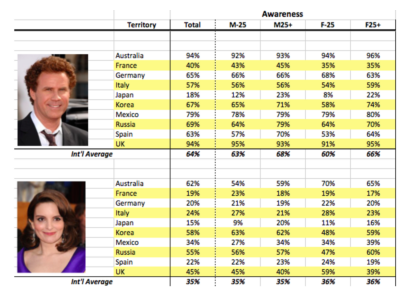

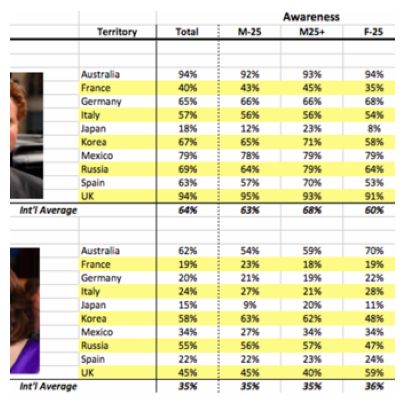

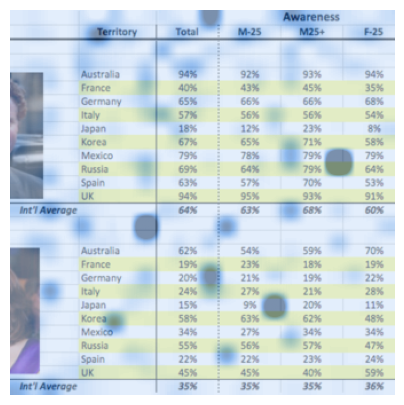

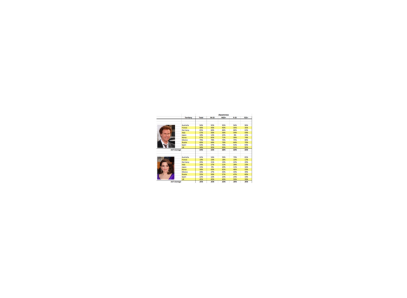

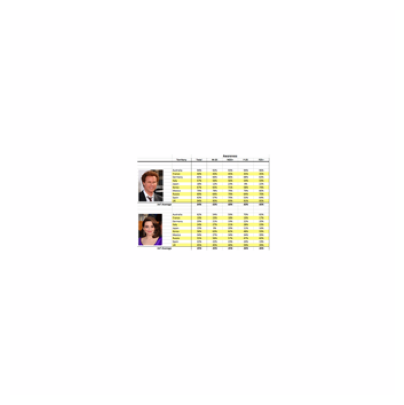

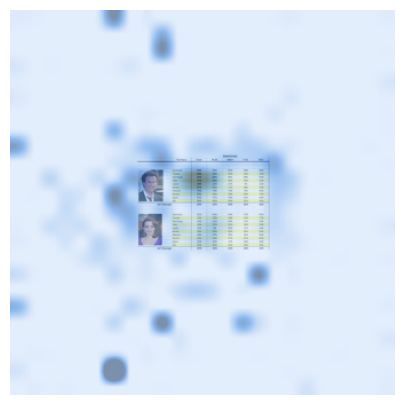

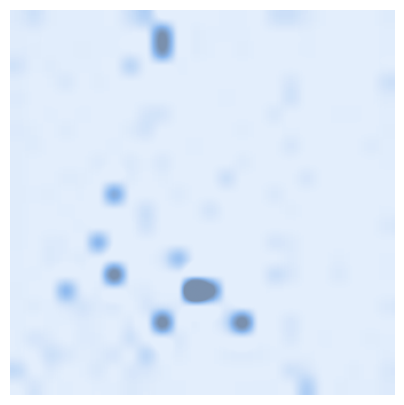

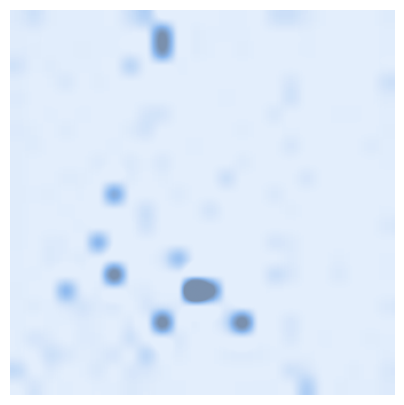

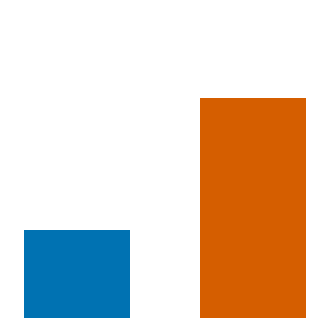

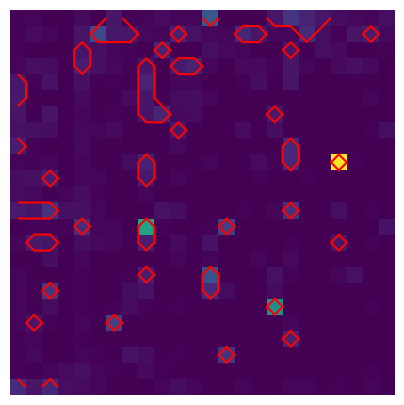

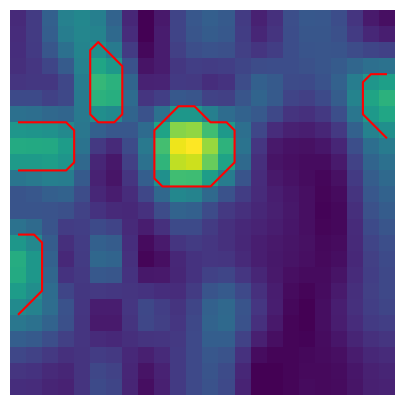

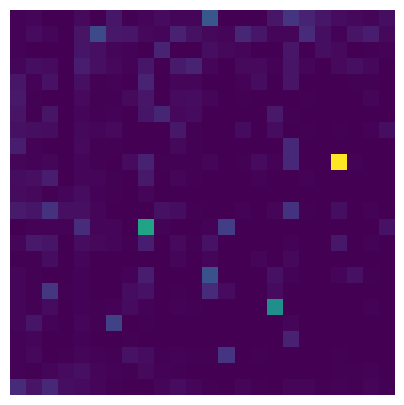

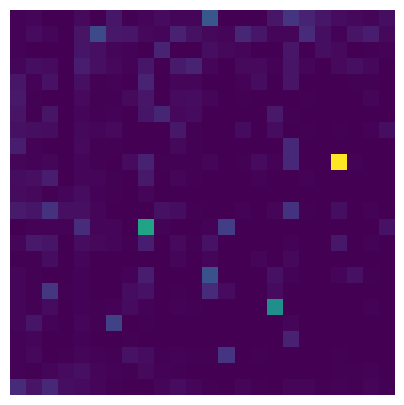

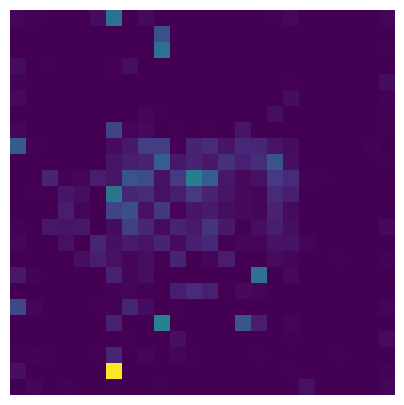

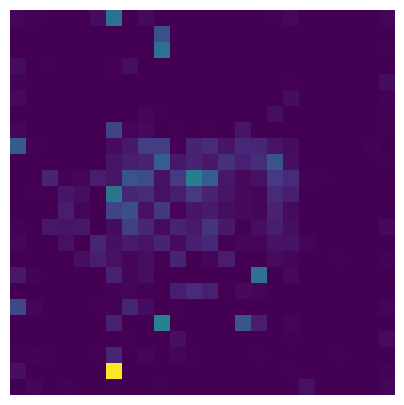


Qwen/Qwen2-VL-7B-Instruct
Running: /home/colligo/Waldo/.venv/bin/python /home/colligo/Waldo/attention_analysis/compute_attention.py --model qwen --benchmark MMVet --id v1_25 --field 3.0 --output-dir /home/colligo/Waldo/attention_analysis/results


2026-07-27 14:30:12,685 - INFO - Loaded 200 samples from MMVet dataset


Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:3


2026-07-27 14:30:14,405 - INFO - Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:3 (attn_implementation=eager for the language model, sdpa for vision)
Loading weights: 100%|██████████| 730/730 [00:03<00:00, 221.53it/s, Materializing param=model.visual.patch_embed.proj.weight]                          
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[original] answer='The total international awareness of Tina Fey is 35%.' score=1.0 (heuristic_contains)
[field=3] OOM on cuda:3 - clearing cache and retrying on the next-best GPU
Moving model cuda:3 -> cuda:0 (GPU load has shifted)


...

Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:3


2026-07-27 14:30:53,816 - INFO - Loading Qwen/Qwen2-VL-7B-Instruct onto cuda:3 (attn_implementation=eager for the language model, sdpa for vision)
Loading weights: 100%|██████████| 730/730 [00:03<00:00, 206.46it/s, Materializing param=model.visual.patch_embed.proj.weight]                          
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[original] answer='The total international awareness of Tina Fey is 35%.' score=1.0 (heuristic_contains)
[field=3] OOM on cuda:3 - clearing cache and retrying on the next-best GPU
Moving model cuda:3 -> cuda:2 (GPU load has shifted)


Traceback (most recent call last):
  File "/home/colligo/Waldo/attention_analysis/compute_attention.py", line 97, in run
    result = cfg["attention_fn"](model, processor, image, question, state["device"],
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/colligo/Waldo/.venv/lib/python3.12/site-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/home/colligo/Waldo/src/attention_viz.py", line 250, in compute_qwen_attention_map
    outputs = model.generate(
              ^^^^^^^^^^^^^^^
  File "/home/colligo/Waldo/.venv/lib/python3.12/site-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/home/colligo/Waldo/.venv/lib/python3.12/site-packages/transformers/generation/utils.py", line 2638, in generate
    result = decoding_method(
             ^^^^^^^^^^^^^^^^
 

CalledProcessError: Command '['/home/colligo/Waldo/.venv/bin/python', '/home/colligo/Waldo/attention_analysis/compute_attention.py', '--model', 'qwen', '--benchmark', 'MMVet', '--id', 'v1_25', '--field', '3.0', '--output-dir', '/home/colligo/Waldo/attention_analysis/results']' returned non-zero exit status 1.

In [12]:
for model_key in MODEL_CONFIGS:
    visualize_instance(model_key, BENCHMARK, TARGET_ID, FIELD_VALUE)
